# Project 1, Part 4: Regularization and Transfer to Data B

In [39]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.optim as optim

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("DEVICE:", DEVICE)

DEVICE: cuda


In [40]:
SOURCE_A_TRAIN = pd.read_csv("./dataset/dataset_a_train.csv")
SOURCE_A_TEST = pd.read_csv("./dataset/dataset_a_test.csv")
SOURCE_B_TEST = pd.read_csv("./dataset/dataset_b_test.csv")
print(SOURCE_A_TRAIN.shape, SOURCE_A_TEST.shape, SOURCE_B_TEST.shape)

LABELS = pd.DataFrame({
    "Label": range(1, 6),
    "Set A": ["Politics", "Sports", "Business", "Technology", "Entertainment"],
}).set_index("Label")

(7500, 3) (2500, 3) (2225, 3)


In [41]:
import copy
import json
import os

import joblib
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score)

SEED = 0              # same seed as Part 2
CLASS_IDS = [1, 2, 3, 4, 5]
NUM_CLASSES = len(CLASS_IDS)
MAX_EPOCHS = 30       # upper limit during the validation sweep
PATIENCE = 5          # early stopping patience (epochs without val macro-F1 gain)
P3_BATCH_SIZE = 64

os.makedirs("results/part3", exist_ok=True)
os.makedirs("models", exist_ok=True)


def set_seed(seed=SEED):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def article_text(df):
    # title + description, same as concat_article but safe for missing values
    return (df["Title"].fillna("").astype(str) + " " + df["Description"].fillna("").astype(str))

In [42]:
class RegMLP(nn.Module):
    """Same architecture as the Part 2 CustomMLP (input -> 128 -> 64 -> 5, ReLU),
    with the dropout rates exposed so Part 3 can vary them."""
    def __init__(self, input_dim, output_dim, dropout=(0.2, 0.3)):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(input_dim, 128), nn.ReLU(), nn.Dropout(dropout[0]),
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(dropout[1]),
            nn.Linear(64, output_dim),
        )

    def forward(self, x):
        return self.layers(x)


def build_model(kind, input_dim, dropout=(0.0, 0.0)):
    if kind == "lr":
        return nn.Linear(input_dim, NUM_CLASSES)  # multinomial logistic regression
    return RegMLP(input_dim, NUM_CLASSES, dropout)

In [43]:
def batches(X, y=None, batch_size=P3_BATCH_SIZE, shuffle=False, rng=None):
    """Densify one batch at a time so the full TF-IDF matrix never sits on the GPU."""
    idx = np.arange(X.shape[0])
    if shuffle:
        rng.shuffle(idx)
    for start in range(0, len(idx), batch_size):
        b = idx[start:start + batch_size]
        xb = torch.tensor(X[b].toarray(), dtype=torch.float32, device=DEVICE)
        if y is None:
            yield xb
        else:
            yield xb, torch.tensor(y[b], dtype=torch.long, device=DEVICE)


def predict(model, X):
    model.eval()
    preds = []
    with torch.inference_mode():
        for xb in batches(X):
            preds.append(model(xb).argmax(dim=1).cpu().numpy())
    return np.concatenate(preds) + 1  # back to labels 1-5


def evaluate(y_true, y_pred, labels=CLASS_IDS):
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)),
        "per_class": classification_report(y_true, y_pred, labels=labels,
                                           output_dict=True, zero_division=0),
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=labels).tolist(),
    }


def train_model(kind, setting, X_train, y_train, X_val=None, y_val=None,
                epochs=MAX_EPOCHS, seed=SEED):
    """Train one model. y values are the original labels 1-5.
    With validation data: early stopping on validation macro-F1, keeps the best epoch.
    Without validation data: trains for exactly `epochs` epochs (used for the refit)."""
    set_seed(seed)
    rng = np.random.default_rng(seed)
    model = build_model(kind, X_train.shape[1], setting.get("dropout", (0.0, 0.0))).to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=setting["lr"],
                           weight_decay=setting["weight_decay"])
    criterion = nn.CrossEntropyLoss()
    y_train0 = np.asarray(y_train) - 1  # CrossEntropyLoss wants 0-indexed labels

    best_f1, best_epoch, best_state, bad = -1.0, 0, None, 0
    history = []
    for epoch in range(1, epochs + 1):
        model.train()
        total = 0.0
        for xb, yb in batches(X_train, y_train0, shuffle=True, rng=rng):
            loss = criterion(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(yb)
        row = {"epoch": epoch, "train_loss": total / X_train.shape[0]}

        if X_val is not None:
            row["val_macro_f1"] = evaluate(y_val, predict(model, X_val))["macro_f1"]
            history.append(row)
            if row["val_macro_f1"] > best_f1:
                best_f1, best_epoch, bad = row["val_macro_f1"], epoch, 0
                best_state = copy.deepcopy(model.state_dict())
            else:
                bad += 1
                if bad >= PATIENCE:
                    break
        else:
            history.append(row)

    if X_val is not None:
        model.load_state_dict(best_state)
    else:
        best_epoch = epochs
    return model, best_epoch, history

### Regularization settings
Logistic regression: L2 penalty through `weight_decay`. MLP: dropout and L2 `weight_decay`, from none to strong. Both use Adam and early stopping on Data A validation macro-F1.

In [44]:
LR_SETTINGS = {
    "lr_wd0":    {"lr": 1e-2, "weight_decay": 0.0},
    "lr_wd1e-5": {"lr": 1e-2, "weight_decay": 1e-5},
    "lr_wd1e-4": {"lr": 1e-2, "weight_decay": 1e-4},
    "lr_wd1e-3": {"lr": 1e-2, "weight_decay": 1e-3},
}

MLP_SETTINGS = {
    "mlp_none":       {"lr": 1e-3, "weight_decay": 0.0,  "dropout": (0.0, 0.0)},
    "mlp_dropout":    {"lr": 1e-3, "weight_decay": 0.0,  "dropout": (0.2, 0.3)},
    "mlp_dropout_wd": {"lr": 1e-3, "weight_decay": 1e-4, "dropout": (0.2, 0.3)},
    "mlp_strong":     {"lr": 1e-3, "weight_decay": 1e-3, "dropout": (0.5, 0.5)},
}

ALL_SETTINGS = {**{k: ("lr", v) for k, v in LR_SETTINGS.items()},
                **{k: ("mlp", v) for k, v in MLP_SETTINGS.items()}}

### Step 1: Sweep on the Data A validation split

In [45]:
# Same stratified 80/20 split as Part 2 (same random_state)
p3_train, p3_val = train_test_split(SOURCE_A_TRAIN, test_size=0.2,
                                    random_state=SEED, stratify=SOURCE_A_TRAIN["Label"])

p3_vec = TfidfVectorizer()  # raw unigram, fit on the 80% training split only
X_tr = p3_vec.fit_transform(article_text(p3_train))
X_val = p3_vec.transform(article_text(p3_val))
y_tr = p3_train["Label"].to_numpy()
y_val = p3_val["Label"].to_numpy()
print("train:", X_tr.shape, " val:", X_val.shape)

sweep_rows, best_epochs, histories = [], {}, {}
for name, (kind, setting) in ALL_SETTINGS.items():
    model, best_epoch, hist = train_model(kind, setting, X_tr, y_tr, X_val, y_val)
    m = evaluate(y_val, predict(model, X_val))
    best_epochs[name], histories[name] = best_epoch, hist
    sweep_rows.append({
        "setting": name, "model": kind.upper(), "lr": setting["lr"],
        "weight_decay": setting["weight_decay"], "dropout": str(setting.get("dropout", "n/a")),
        "best_epoch": best_epoch, "val_accuracy": m["accuracy"], "val_macro_f1": m["macro_f1"],
    })
    print(f"{name:16s} best_epoch={best_epoch:2d}  val acc={m['accuracy']:.4f}  val macro-F1={m['macro_f1']:.4f}")

sweep_df = pd.DataFrame(sweep_rows)
sweep_df.to_csv("results/part3/validation_sweep.csv", index=False)
display(sweep_df)

train: (6000, 17857)  val: (1500, 17857)
lr_wd0           best_epoch= 4  val acc=0.8100  val macro-F1=0.8100
lr_wd1e-5        best_epoch= 6  val acc=0.8100  val macro-F1=0.8103
lr_wd1e-4        best_epoch= 5  val acc=0.8053  val macro-F1=0.8060
lr_wd1e-3        best_epoch= 1  val acc=0.7853  val macro-F1=0.7857
mlp_none         best_epoch= 2  val acc=0.8020  val macro-F1=0.8025
mlp_dropout      best_epoch= 2  val acc=0.8040  val macro-F1=0.8045
mlp_dropout_wd   best_epoch= 2  val acc=0.7973  val macro-F1=0.7979
mlp_strong       best_epoch= 9  val acc=0.7920  val macro-F1=0.7923


,setting,model,lr,weight_decay,dropout,best_epoch,val_accuracy,val_macro_f1
0,lr_wd0,LR,0.010,0.00000,n/a,4,0.810000,0.810021
1,lr_wd1e-5,LR,0.010,0.00001,n/a,6,0.810000,0.810313
2,lr_wd1e-4,LR,0.010,0.00010,n/a,5,0.805333,0.806006
3,lr_wd1e-3,LR,0.010,0.00100,n/a,1,0.785333,0.785671
4,mlp_none,MLP,0.001,0.00000,"(0.0, 0.0)",2,0.802000,0.802496
5,mlp_dropout,MLP,0.001,0.00000,"(0.2, 0.3)",2,0.804000,0.804527
6,mlp_dropout_wd,MLP,0.001,0.00010,"(0.2, 0.3)",2,0.797333,0.797937
7,mlp_strong,MLP,0.001,0.00100,"(0.5, 0.5)",9,0.792000,0.792338


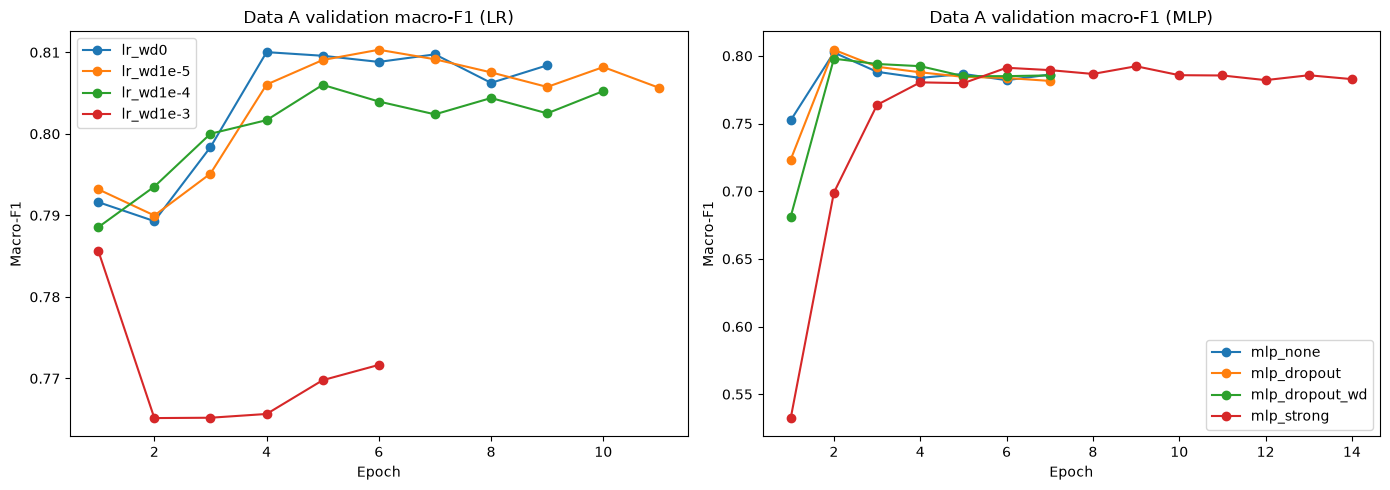

In [46]:
# Validation macro-F1 per epoch for every setting
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, kind in zip(axes, ["lr", "mlp"]):
    for name, (k, _) in ALL_SETTINGS.items():
        if k == kind:
            h = pd.DataFrame(histories[name])
            ax.plot(h["epoch"], h["val_macro_f1"], marker="o", label=name)
    ax.set_title(f"Data A validation macro-F1 ({kind.upper()})")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Macro-F1")
    ax.legend()
plt.tight_layout()
plt.savefig("results/part3/validation_curves.png", dpi=150)
plt.show()

### Step 2: Select one setting per model (validation only)
The selection is saved before any test set is touched.

In [47]:
best_lr = sweep_df[sweep_df.model == "LR"].sort_values("val_macro_f1", ascending=False).iloc[0]["setting"]
best_mlp = sweep_df[sweep_df.model == "MLP"].sort_values("val_macro_f1", ascending=False).iloc[0]["setting"]

selection = {
    "seed": SEED,
    "criterion": "highest Data A validation macro-F1",
    "selected_lr": best_lr, "lr_config": ALL_SETTINGS[best_lr][1], "lr_epochs": best_epochs[best_lr],
    "selected_mlp": best_mlp, "mlp_config": ALL_SETTINGS[best_mlp][1], "mlp_epochs": best_epochs[best_mlp],
}
with open("results/part3/selection.json", "w") as f:
    json.dump(selection, f, indent=2)
print(json.dumps(selection, indent=2))

{
  "seed": 0,
  "criterion": "highest Data A validation macro-F1",
  "selected_lr": "lr_wd1e-5",
  "lr_config": {
    "lr": 0.01,
    "weight_decay": 1e-05
  },
  "lr_epochs": 6,
  "selected_mlp": "mlp_dropout",
  "mlp_config": {
    "lr": 0.001,
    "weight_decay": 0.0,
    "dropout": [
      0.2,
      0.3
    ]
  },
  "mlp_epochs": 2
}


### Step 3: Refit on all of Data A train, evaluate on Data A test and Data B test
The refit trains for the best epoch count found on validation, since there is no validation set left to early-stop on.

In [48]:
vec_full = TfidfVectorizer()  # refit on ALL of dataset_a_train.csv
X_a_full = vec_full.fit_transform(article_text(SOURCE_A_TRAIN))
y_a_full = SOURCE_A_TRAIN["Label"].to_numpy()
X_a_test = vec_full.transform(article_text(SOURCE_A_TEST))
y_a_test = SOURCE_A_TEST["Label"].to_numpy()
X_b_test = vec_full.transform(article_text(SOURCE_B_TEST))  # transform only, never fit
y_b_test = SOURCE_B_TEST["Label"].to_numpy()
print("vocab size:", len(vec_full.vocabulary_))

FINAL_MODELS, final_results = {}, {}
for tag, name in [("lr", best_lr), ("mlp", best_mlp)]:
    kind, setting = ALL_SETTINGS[name]
    model, _, _ = train_model(kind, setting, X_a_full, y_a_full, epochs=best_epochs[name])
    FINAL_MODELS[tag] = model
    torch.save(model.state_dict(), f"models/part3_final_{tag}.pt")
    final_results[tag] = {
        "setting": name, "config": setting, "epochs": best_epochs[name], "seed": SEED,
        "representation": "unigram TF-IDF, title + description",
        "train_data": "all of dataset_a_train.csv", "train_size": len(SOURCE_A_TRAIN),
        "A_test": evaluate(y_a_test, predict(model, X_a_test)),
        "B_test": evaluate(y_b_test, predict(model, X_b_test)),
    }
joblib.dump(vec_full, "models/part3_vectorizer.joblib")

with open("results/part3/final_results.json", "w") as f:
    json.dump(final_results, f, indent=2)

summary = pd.DataFrame([{
    "model": tag.upper(), "setting": r["setting"],
    "A_test_acc": r["A_test"]["accuracy"], "A_test_macro_f1": r["A_test"]["macro_f1"],
    "B_test_acc": r["B_test"]["accuracy"], "B_test_macro_f1": r["B_test"]["macro_f1"],
} for tag, r in final_results.items()])
display(summary)

vocab size: 19834


,model,setting,A_test_acc,A_test_macro_f1,B_test_acc,B_test_macro_f1
0,LR,lr_wd1e-5,0.5648,0.564727,0.780225,0.788776
1,MLP,mlp_dropout,0.5784,0.574852,0.792360,0.794088


,model,label,class,A_precision,A_recall,A_f1,B_precision,B_recall,B_f1,f1_drop
0,LR,1,Politics,0.383,0.374,0.379,0.938,0.542,0.687,-0.308
1,LR,2,Sports,0.652,0.664,0.658,0.982,0.871,0.923,-0.265
2,LR,3,Business,0.612,0.564,0.587,0.527,0.990,0.688,-0.101
3,LR,4,Technology,0.683,0.684,0.683,0.981,0.643,0.777,-0.094
4,LR,5,Entertainment,0.497,0.538,0.517,0.977,0.782,0.869,-0.352
5,MLP,1,Politics,0.404,0.372,0.388,0.874,0.468,0.609,-0.222
6,MLP,2,Sports,0.667,0.696,0.681,0.983,0.896,0.938,-0.257
7,MLP,3,Business,0.612,0.552,0.580,0.556,0.986,0.711,-0.131
8,MLP,4,Technology,0.662,0.748,0.702,0.931,0.746,0.828,-0.126
9,MLP,5,Entertainment,0.522,0.524,0.523,0.990,0.798,0.884,-0.361


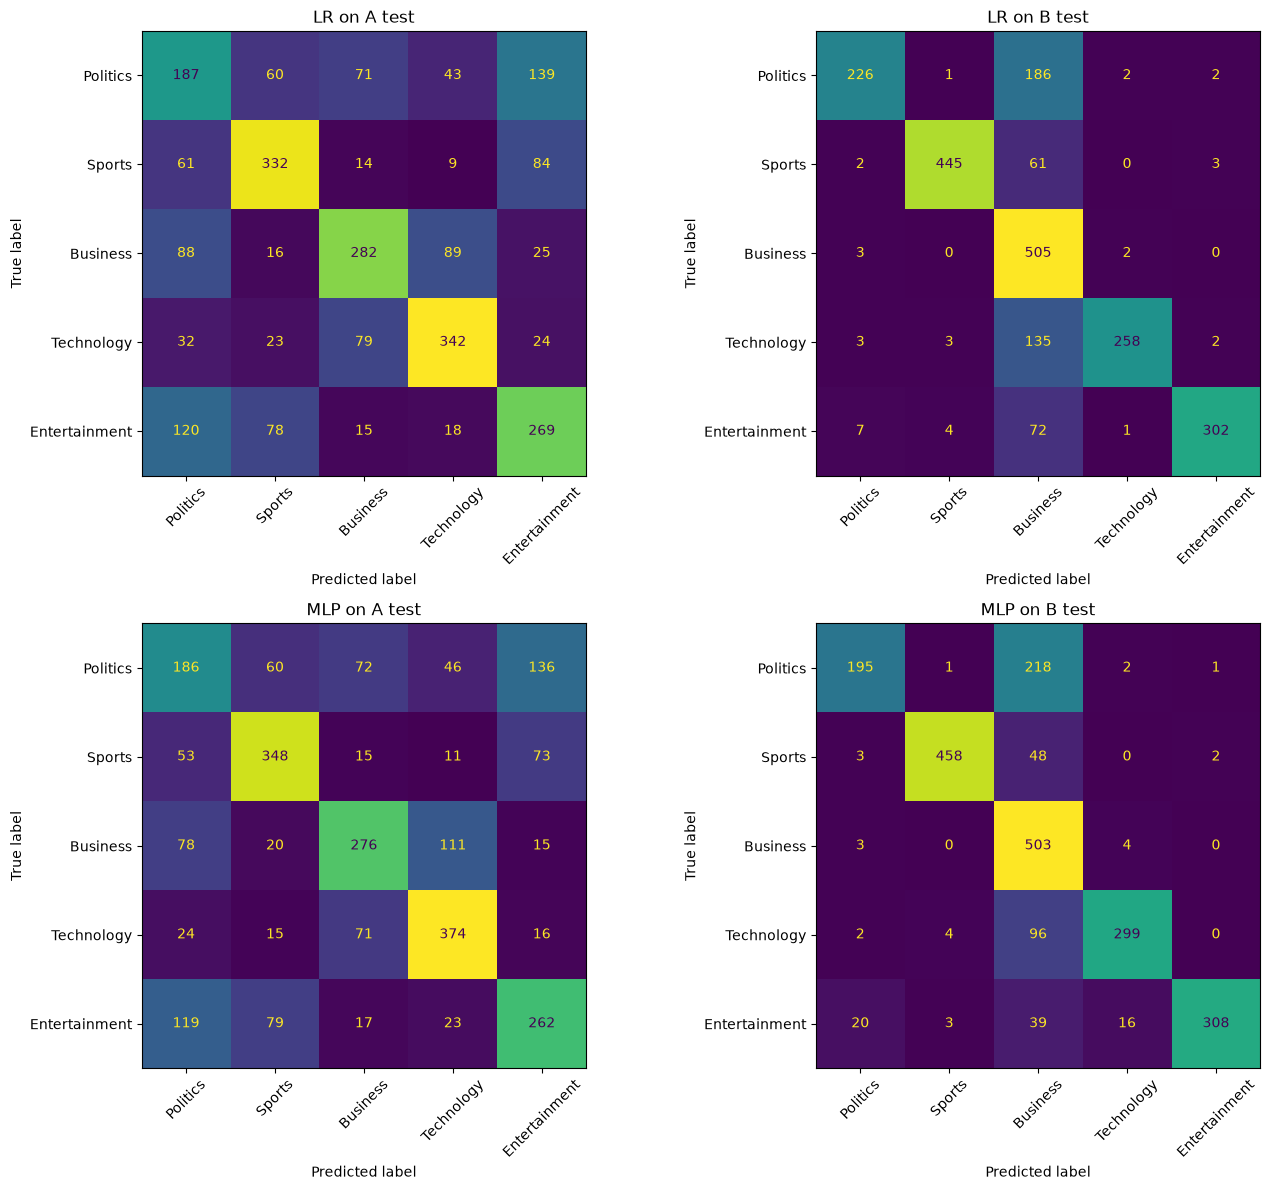

In [49]:
# Per-class precision / recall / F1, Data A vs Data B
rows = []
for tag, r in final_results.items():
    for lab in CLASS_IDS:
        a, b = r["A_test"]["per_class"][str(lab)], r["B_test"]["per_class"][str(lab)]
        rows.append({"model": tag.upper(), "label": lab, "class": LABELS.loc[lab, "Set A"],
                     "A_precision": a["precision"], "A_recall": a["recall"], "A_f1": a["f1-score"],
                     "B_precision": b["precision"], "B_recall": b["recall"], "B_f1": b["f1-score"],
                     "f1_drop": a["f1-score"] - b["f1-score"]})
per_class = pd.DataFrame(rows)
per_class.to_csv("results/part3/per_class_A_vs_B.csv", index=False)
display(per_class.round(3))

# Confusion matrices
class_names = list(LABELS["Set A"])
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for i, tag in enumerate(["lr", "mlp"]):
    for j, ds in enumerate(["A_test", "B_test"]):
        cm = np.array(final_results[tag][ds]["confusion_matrix"])
        ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
            ax=axes[i, j], colorbar=False, xticks_rotation=45)
        axes[i, j].set_title(f"{tag.upper()} on {ds.replace('_', ' ')}")
plt.tight_layout()
plt.savefig("results/part3/confusion_matrices.png", dpi=150)
plt.show()

### Step 4 (post hoc): every setting on the test sets
Reported for analysis only. These numbers were not used to pick the final models.

In [50]:
posthoc = []
for name, (kind, setting) in ALL_SETTINGS.items():
    model, _, _ = train_model(kind, setting, X_a_full, y_a_full, epochs=best_epochs[name])
    fa = evaluate(y_a_test, predict(model, X_a_test))["macro_f1"]
    fb = evaluate(y_b_test, predict(model, X_b_test))["macro_f1"]
    posthoc.append({"setting": name, "model": kind.upper(),
                    "A_test_macro_f1": fa, "B_test_macro_f1": fb, "A_minus_B": fa - fb})
posthoc_df = pd.DataFrame(posthoc)
posthoc_df.to_csv("results/part3/posthoc_all_settings.csv", index=False)
display(posthoc_df.round(4))

,setting,model,A_test_macro_f1,B_test_macro_f1,A_minus_B
0,lr_wd0,LR,0.5599,0.7864,-0.2266
1,lr_wd1e-5,LR,0.5647,0.7888,-0.2240
2,lr_wd1e-4,LR,0.5626,0.7597,-0.1971
3,lr_wd1e-3,LR,0.5472,0.5494,-0.0021
4,mlp_none,MLP,0.5749,0.8230,-0.2482
5,mlp_dropout,MLP,0.5749,0.7941,-0.2192
6,mlp_dropout_wd,MLP,0.5723,0.7797,-0.2075
7,mlp_strong,MLP,0.5521,0.7349,-0.1829


### Step 5: Transfer diagnostics (for the A vs B discussion)
Class balance, text length in words, and out-of-vocabulary rate relative to the Data A vocabulary.

In [51]:
def word_count(s):
    return s.fillna("").astype(str).str.split().str.len()

analyzer, vocab = vec_full.build_analyzer(), vec_full.vocabulary_
diag_rows = []
for dname, df in [("A_train", SOURCE_A_TRAIN), ("A_test", SOURCE_A_TEST), ("B_test", SOURCE_B_TEST)]:
    toks = [t for doc in article_text(df) for t in analyzer(doc)]
    props = df["Label"].value_counts(normalize=True).sort_index()
    diag_rows.append({
        "dataset": dname, "n": len(df),
        **{f"pct_label_{k}": round(100 * props.get(k, 0), 1) for k in CLASS_IDS},
        "title_words_median": word_count(df["Title"]).median(),
        "desc_words_median": word_count(df["Description"]).median(),
        "oov_rate_vs_A_vocab": round(float(np.mean([t not in vocab for t in toks])), 4),
    })
diag_df = pd.DataFrame(diag_rows)
diag_df.to_csv("results/part3/transfer_diagnostics.csv", index=False)
display(diag_df)

,dataset,n,pct_label_1,pct_label_2,pct_label_3,pct_label_4,pct_label_5,title_words_median,desc_words_median,oov_rate_vs_A_vocab
0,A_train,7500,20.0,20.0,20.0,20.0,20.0,10.0,17.0,0.0000
1,A_test,2500,20.0,20.0,20.0,20.0,20.0,11.0,15.0,0.0528
2,B_test,2225,18.7,23.0,22.9,18.0,17.3,5.0,326.0,0.0736


Checking whether duplicate articles explain the gap between validation and A test scores.

In [52]:
dup_rows = SOURCE_A_TRAIN.duplicated().sum()
dup_text = article_text(SOURCE_A_TRAIN).duplicated().sum()
train_text = set(article_text(p3_train))
val_overlap = article_text(p3_val).isin(train_text).sum()
test_overlap = article_text(SOURCE_A_TEST).isin(set(article_text(SOURCE_A_TRAIN))).sum()
print("duplicate rows in A train:", dup_rows)
print("duplicate texts in A train:", dup_text)
print("val articles also in train split:", val_overlap, "/", len(p3_val))
print("A test articles also in A train:", test_overlap, "/", len(SOURCE_A_TEST))

duplicate rows in A train: 47
duplicate texts in A train: 47
val articles also in train split: 15 / 1500
A test articles also in A train: 0 / 2500


### Frozen models for Part 4
`FINAL_MODELS["lr"]`, `FINAL_MODELS["mlp"]`, and `vec_full` stay in memory. They are also saved to `models/`. To reload them in a fresh session:

```python
vec_full = joblib.load("models/part3_vectorizer.joblib")
n_feat = len(vec_full.vocabulary_)
FINAL_MODELS = {}
for tag in ["lr", "mlp"]:
    kind, setting = ALL_SETTINGS[selection[f"selected_{tag}"]]
    m = build_model(kind, n_feat, setting.get("dropout", (0.0, 0.0))).to(DEVICE)
    m.load_state_dict(torch.load(f"models/part3_final_{tag}.pt", map_location=DEVICE))
    FINAL_MODELS[tag] = m.eval()
```

# Part 4: Transfer to Data C and Analysis of Label 1
Continues directly from Part 3: uses `FINAL_MODELS`, `vec_full`, `selection`, and the Part 3 helpers (`predict`, `train_model`, `ALL_SETTINGS`, ...) already defined above. Part 3 models and vectorizer stay frozen; `dataset_c_train.csv` is used only for the separate in-domain reference models; `dataset_c_test.csv` is never used to fit or select anything.

### Part 4 helper functions for metrics, error analysis, and leakage checks

In [53]:
import hashlib
from collections import Counter

import numpy as np
import pandas as pd
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_recall_fscore_support)

A_LABELS = [1, 2, 3, 4, 5]      # label space of the Data A trained models
C_LABELS = [1, 2, 3, 4]         # label space present in Data C
SHARED = [2, 3, 4]              # labels with identical meaning in A and C


# Data handling
def normalize_columns(df):
    """Accept 'label/title/description' (handout) or 'Label/Title/Description' (our notebook)."""
    mapping = {c: c.strip().capitalize() for c in df.columns
               if c.strip().lower() in ("label", "title", "description")}
    out = df.rename(columns=mapping)
    missing = {"Label", "Title", "Description"} - set(out.columns)
    if missing:
        raise ValueError(f"missing columns: {missing}")
    return out


def article_text(df):
    """title + description, safe for missing values (same as Part 3)."""
    return df["Title"].fillna("").astype(str) + " " + df["Description"].fillna("").astype(str)


def text_overlap(texts_a, texts_b):
    """Number of texts in `texts_a` that also appear verbatim in `texts_b` (leakage check)."""
    return int(pd.Series(list(texts_a)).isin(set(texts_b)).sum())


def fingerprint(arrays):
    """SHA-256 over a list of numpy arrays; used to prove frozen weights never changed."""
    h = hashlib.sha256()
    for a in arrays:
        a = np.ascontiguousarray(a)
        h.update(str(a.shape).encode())
        h.update(a.tobytes())
    return h.hexdigest()


# Metrics
def shared_label_metrics(y_true, y_pred, shared=SHARED):
    """Shared-label transfer: keep only rows whose TRUE label is in `shared`.

    Accuracy counts a prediction of 1 or 5 as an error. Macro-F1 is averaged over
    exactly `shared` (labels=[2,3,4]); a wrong 1/5 prediction still lowers recall of the
    true class. Predictions are NOT restricted/renormalised to 2-4.
    """
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    mask = np.isin(y_true, shared)
    yt, yp = y_true[mask], y_pred[mask]
    return {
        "n": int(mask.sum()),
        "accuracy": float(accuracy_score(yt, yp)),
        "macro_f1": float(f1_score(yt, yp, labels=shared, average="macro", zero_division=0)),
        "frac_predicted_outside_shared": float(np.mean(~np.isin(yp, shared))),
    }


def label_prf(y_true, y_pred, label=1, labels=A_LABELS):
    """Precision/recall/F1 for one label over ALL rows of the evaluation set, plus
    the full row of predictions for rows whose true label is `label`."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    p, r, f, s = precision_recall_fscore_support(
        y_true, y_pred, labels=[label], zero_division=0)
    true_rows = y_true == label
    counts = Counter(y_pred[true_rows].tolist())
    return {
        "label": label,
        "precision": float(p[0]), "recall": float(r[0]), "f1": float(f[0]),
        "support": int(s[0]),
        "n_predicted_as_label": int((y_pred == label).sum()),
        "predicted_as": {int(l): int(counts.get(l, 0)) for l in labels},
    }


def overall_metrics(y_true, y_pred, labels=C_LABELS):
    """Accuracy over all rows and macro-F1 over `labels` (default 1-4)."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)),
    }


def pct_predicted(y_pred, label=5):
    """Percentage (0-100) of all predictions equal to `label`."""
    y_pred = np.asarray(y_pred)
    return float(100.0 * np.mean(y_pred == label))


def rect_confusion(y_true, y_pred, true_labels=C_LABELS, pred_labels=A_LABELS):
    """Rows = true labels present in the eval set, columns = every label the model can output."""
    full = confusion_matrix(y_true, y_pred, labels=sorted(set(true_labels) | set(pred_labels)))
    order = sorted(set(true_labels) | set(pred_labels))
    r = [order.index(l) for l in true_labels]
    c = [order.index(l) for l in pred_labels]
    return full[np.ix_(r, c)]


def per_class_table(y_true, y_pred, labels=A_LABELS, names=None):
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    df = pd.DataFrame({"label": labels, "precision": p, "recall": r, "f1": f, "support": s})
    if names:
        df.insert(1, "class", [names.get(l, str(l)) for l in labels])
    return df


# Error analysis for Data C label 1 (World)
def sample_errors(df, y_pred, label=1, n=10, seed=0):
    """Sample n misclassified examples whose true label is `label`.

    Round-robin over predicted labels so the sample shows every kind of mistake
    (e.g. World -> Politics vs World -> Business) rather than only the most common one.
    Returns every error if there are fewer than n.
    """
    y_true = df["Label"].to_numpy()
    y_pred = np.asarray(y_pred)
    err = np.where((y_true == label) & (y_pred != label))[0]
    rng = np.random.default_rng(seed)
    groups = {}
    for i in rng.permutation(err):
        groups.setdefault(int(y_pred[i]), []).append(i)
    picked, keys = [], sorted(groups, key=lambda k: -len(groups[k]))
    while len(picked) < min(n, len(err)):
        for k in keys:
            if groups[k] and len(picked) < n:
                picked.append(groups[k].pop())
    out = df.iloc[picked][["Label", "Title", "Description"]].copy()
    out.insert(1, "Predicted", y_pred[picked])
    return out.reset_index().rename(columns={"index": "row"})


# Heuristic keyword buckets for describing World articles. STARTING POINT:
WORLD_TOPICS = {
    "conflict/security": ["iraq", "afghanistan", "militants", "troops", "attack", "bomb", "killed",
                          "hostage", "rebels", "insurgents", "war", "terror", "army", "police"],
    "disaster/health": ["earthquake", "flood", "storm", "hurricane", "typhoon", "tsunami", "crash",
                        "virus", "outbreak", "disease", "bird flu", "sars", "famine"],
    "foreign leaders/diplomacy": ["prime minister", "president", "minister", "talks", "summit",
                                  "un ", "united nations", "nato", "eu ", "treaty", "sanctions"],
    "nuclear/arms": ["nuclear", "iran", "north korea", "missile", "weapons", "uranium"],
    "region-specific": ["china", "japan", "india", "pakistan", "russia", "israel", "palestinian",
                        "africa", "europe", "asia", "korea", "sudan", "haiti"],
    "domestic US politics": ["senate", "congress", "white house", "bush", "kerry", "election",
                             "campaign", "republican", "democrat", "supreme court"],
}


def tag_topics(text, topics=WORLD_TOPICS):
    t = " " + str(text).lower() + " "
    hits = [name for name, kws in topics.items() if any(k in t for k in kws)]
    return hits or ["other"]


def topic_breakdown(df, y_pred, label=1, topics=WORLD_TOPICS):
    """For each topic bucket: how many true `label` articles hit it and how many were recalled."""
    y_true = df["Label"].to_numpy()
    y_pred = np.asarray(y_pred)
    rows = Counter(), Counter()
    for text, yt, yp in zip(article_text(df), y_true, y_pred):
        if yt != label:
            continue
        for tpc in tag_topics(text, topics):
            rows[0][tpc] += 1
            rows[1][tpc] += int(yp == label)
    out = pd.DataFrame({"n_articles": rows[0], "n_correct": rows[1]}).fillna(0).astype(int)
    out["recall"] = out["n_correct"] / out["n_articles"]
    return out.sort_values("n_articles", ascending=False)


def vocab_gap(world_texts, politics_texts, analyzer, min_world_df=3):
    """Tokens frequent in Data C World articles but absent/rare in Data A Politics.

    world_texts: texts to analyse (e.g. the missed World articles, or all World test articles)
    politics_texts: Data A TRAIN texts with label 1
    analyzer: vec_full.build_analyzer() so tokenisation matches the model
    Returns document frequencies (not counts) so one long article can't dominate.
    """
    wdf, pdf_ = Counter(), Counter()
    for t in world_texts:
        wdf.update(set(analyzer(t)))
    for t in politics_texts:
        pdf_.update(set(analyzer(t)))
    n_w, n_p = max(len(world_texts), 1), max(len(politics_texts), 1)
    rows = [{"token": tok, "world_df": c, "world_df_pct": 100 * c / n_w,
             "politics_A_df": pdf_.get(tok, 0), "politics_A_df_pct": 100 * pdf_.get(tok, 0) / n_p}
            for tok, c in wdf.items() if c >= min_world_df]
    df = pd.DataFrame(rows)
    if df.empty:
        return df
    df["ratio"] = (df["world_df_pct"] + 1e-6) / (df["politics_A_df_pct"] + 0.05)
    return df.sort_values(["ratio", "world_df"], ascending=False).reset_index(drop=True)


def oov_rate(texts, vocab_dict, analyzer):
    toks = [t for doc in texts for t in analyzer(doc)]
    return float(np.mean([t not in vocab_dict for t in toks])) if toks else 0.0


# Uncertainty
def bootstrap_ci(y_true, y_pred, metric_fn, n_boot=1000, seed=0, alpha=0.05):
    """Percentile bootstrap CI for any metric_fn(y_true, y_pred) -> float.

    Useful for judging whether a label-1 F1 gap (transferred vs in-domain reference)
    is bigger than sampling noise on the Data C test set.
    """
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    rng = np.random.default_rng(seed)
    n = len(y_true)
    vals = [metric_fn(y_true[i], y_pred[i]) for i in (rng.integers(0, n, n) for _ in range(n_boot))]
    lo, hi = np.percentile(vals, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return float(lo), float(hi)

# expose everything above as `u.` so the Part 4 cells read the same as the standalone module
import types
u = types.SimpleNamespace(**{n: globals()[n] for n in ['A_LABELS', 'C_LABELS', 'SHARED', 'normalize_columns', 'article_text', 'text_overlap', 'fingerprint', 'shared_label_metrics', 'label_prf', 'overall_metrics', 'pct_predicted', 'rect_confusion', 'per_class_table', 'sample_errors', 'WORLD_TOPICS', 'tag_topics', 'topic_breakdown', 'vocab_gap', 'oov_rate', 'bootstrap_ci']})


In [54]:
import contextlib, json, os
import joblib
from IPython.display import display

os.makedirs("results/part4", exist_ok=True)

# Reload frozen Part 3 artifacts if this is a fresh session
if "FINAL_MODELS" not in globals():
    selection = json.load(open("results/part3/selection.json"))
    vec_full = joblib.load("models/part3_vectorizer.joblib")
    FINAL_MODELS = {}
    for tag in ["lr", "mlp"]:
        kind, setting = ALL_SETTINGS[selection[f"selected_{tag}"]]
        m = build_model(kind, len(vec_full.vocabulary_), setting.get("dropout", (0.0, 0.0))).to(DEVICE)
        m.load_state_dict(torch.load(f"models/part3_final_{tag}.pt", map_location=DEVICE))
        FINAL_MODELS[tag] = m.eval()
else:
    selection = json.load(open("results/part3/selection.json"))

if "model_fingerprint" not in globals():
    def model_fingerprint(m):
        return u.fingerprint([v.detach().cpu().numpy() for v in m.state_dict().values()])

FROZEN_FP = {tag: model_fingerprint(m) for tag, m in FINAL_MODELS.items()}
VOCAB_SNAPSHOT = dict(vec_full.vocabulary_)
print("frozen models:", {t: selection[f"selected_{t}"] for t in FINAL_MODELS}, "| vocab size:", len(VOCAB_SNAPSHOT))

frozen models: {'lr': 'lr_wd1e-5', 'mlp': 'mlp_dropout'} | vocab size: 19834


### Load Data C and run leakage

In [55]:
C_TRAIN = u.normalize_columns(pd.read_csv("./dataset/dataset_c_train.csv"))
C_TEST  = u.normalize_columns(pd.read_csv("./dataset/dataset_c_test.csv"))
y_c_test = C_TEST["Label"].to_numpy()
print("C train:", C_TRAIN.shape, " C test:", C_TEST.shape)
print("C test label counts:\n", C_TEST["Label"].value_counts().sort_index().to_string())

# sanity checks (fail loudly instead of reporting wrong numbers)
assert set(C_TEST["Label"]) == {1, 2, 3, 4}, "Data C test should have labels 1-4 only"
assert u.text_overlap(u.article_text(C_TEST), u.article_text(C_TRAIN)) >= 0
print("C test texts also in C train:", u.text_overlap(u.article_text(C_TEST), u.article_text(C_TRAIN)))
print("C test texts also in A train:", u.text_overlap(u.article_text(C_TEST), u.article_text(SOURCE_A_TRAIN)))

C train: (6000, 3)  C test: (2000, 3)
C test label counts:
 Label
1    500
2    500
3    500
4    500
C test texts also in C train: 0
C test texts also in A train: 0


### Step 1: frozen Data A models on `dataset_c_test.csv` (transform + predict only)

In [56]:
X_c_test = vec_full.transform(u.article_text(C_TEST))      # transform only, never fit
print("C test matrix:", X_c_test.shape, "| OOV rate vs A vocab:",
      round(u.oov_rate(u.article_text(C_TEST), VOCAB_SNAPSHOT, vec_full.build_analyzer()), 4))

PRED_C = {tag: predict(m, X_c_test) for tag, m in FINAL_MODELS.items()}   # labels 1-5

rows = []
for tag, yp in PRED_C.items():
    sh  = u.shared_label_metrics(y_c_test, yp)
    l1  = u.label_prf(y_c_test, yp, label=1)
    ov  = u.overall_metrics(y_c_test, yp)
    rows.append({
        "model": tag.upper(), "setting": selection[f"selected_{tag}"],
        "shared_n": sh["n"], "shared_acc": sh["accuracy"], "shared_macro_f1_2to4": sh["macro_f1"],
        "label1_precision": l1["precision"], "label1_recall": l1["recall"], "label1_f1": l1["f1"],
        "overall_acc_1to4": ov["accuracy"], "overall_macro_f1_1to4": ov["macro_f1"],
        "pct_pred_label5": u.pct_predicted(yp, 5),
        **{f"world_pred_as_{k}": v for k, v in l1["predicted_as"].items()},
    })
transfer_df = pd.DataFrame(rows)
transfer_df.to_csv("results/part4/transfer_summary.csv", index=False)
display(transfer_df.round(4).T)

C test matrix: (2000, 19834) | OOV rate vs A vocab: 0.0949


,0,1
model,LR,MLP
setting,lr_wd1e-5,mlp_dropout
shared_n,1500,1500
shared_acc,0.5867,0.5987
shared_macro_f1_2to4,0.6286,0.6378
label1_precision,0.5923,0.6068
label1_recall,0.43,0.392
label1_f1,0.4983,0.4763
overall_acc_1to4,0.5475,0.547
overall_macro_f1_1to4,0.5608,0.5597


LR


,label,class,precision,recall,f1,support
0,1,World (C) / Politics (A),0.592,0.430,0.498,500
1,2,Sports,0.780,0.846,0.812,500
2,3,Business,0.442,0.512,0.475,500
3,4,Technology,0.533,0.402,0.458,500
4,5,Entertainment (absent in C),0.000,0.000,0.000,0


MLP


,label,class,precision,recall,f1,support
0,1,World (C) / Politics (A),0.607,0.392,0.476,500
1,2,Sports,0.810,0.828,0.819,500
2,3,Business,0.416,0.518,0.461,500
3,4,Technology,0.520,0.450,0.482,500
4,5,Entertainment (absent in C),0.000,0.000,0.000,0


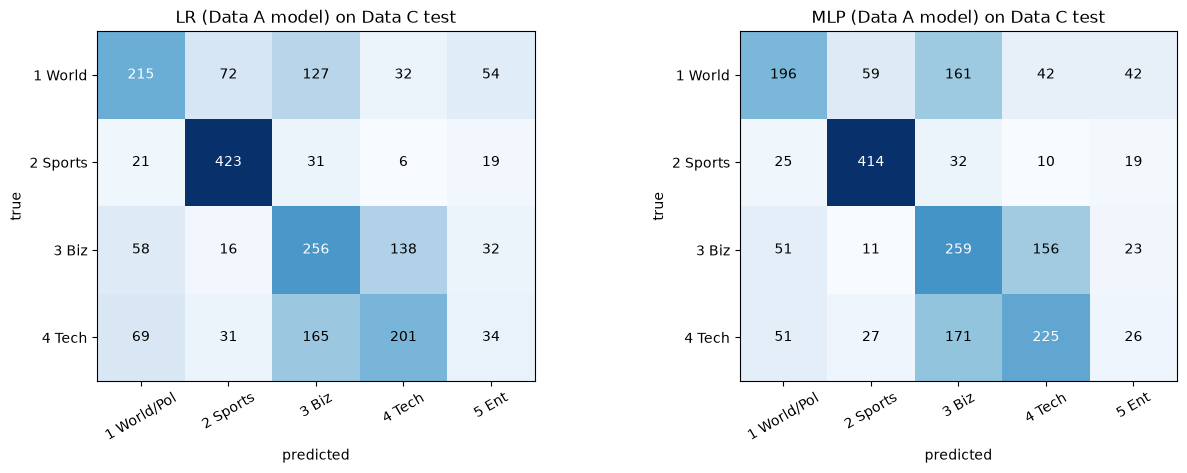

In [57]:
# Per-class report for each model (labels 1-5; label 5 has zero support in Data C)
for tag, yp in PRED_C.items():
    t = u.per_class_table(y_c_test, yp, labels=[1, 2, 3, 4, 5],
                          names={1: "World (C) / Politics (A)", 2: "Sports", 3: "Business",
                                 4: "Technology", 5: "Entertainment (absent in C)"})
    t.to_csv(f"results/part4/per_class_{tag}.csv", index=False)
    print(tag.upper()); display(t.round(3))

# Confusion matrices: rows = true Data C label (1-4), columns = predicted label (1-5)
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (tag, yp) in zip(axes, PRED_C.items()):
    cm = u.rect_confusion(y_c_test, yp)
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(5)); ax.set_xticklabels(["1 World/Pol", "2 Sports", "3 Biz", "4 Tech", "5 Ent"], rotation=30)
    ax.set_yticks(range(4)); ax.set_yticklabels(["1 World", "2 Sports", "3 Biz", "4 Tech"])
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_title(f"{tag.upper()} (Data A model) on Data C test"); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.savefig("results/part4/confusion_matrices.png", dpi=150); plt.show()

### Step 2: error analysis for true Data C label 1 (World)
Three views: (1) at least 10 sampled errors per model, (2) topic buckets (heuristic keyword lists in `u.WORLD_TOPICS`; **edit them after reading the errors**), (3) vocabulary frequent in Data C World but absent/rare in Data A Politics.

In [58]:
N_ERR_SAMPLE = 12
pd.set_option("display.max_colwidth", 220)
for tag, yp in PRED_C.items():
    n_err = int(((y_c_test == 1) & (yp != 1)).sum())
    print(f"\n=== {tag.upper()}: {n_err} of {int((y_c_test == 1).sum())} World articles misclassified ===")
    errs = u.sample_errors(C_TEST, yp, label=1, n=N_ERR_SAMPLE, seed=SEED)
    errs["topics"] = [", ".join(u.tag_topics(f"{t} {d}")) for t, d in zip(errs["Title"], errs["Description"])]
    errs.to_csv(f"results/part4/label1_errors_{tag}.csv", index=False)
    display(errs)

    tb = u.topic_breakdown(C_TEST, yp, label=1)
    tb.to_csv(f"results/part4/label1_topic_recall_{tag}.csv")
    display(tb.round(3))


=== LR: 285 of 500 World articles misclassified ===


,row,Label,Predicted,Title,Description,topics
0,743,1,3,IKEA Touts Its 'Democratic Design' (Reuters),"Reuters - The design chief of home\furnishing giant IKEA was recently asked in China, now home to\two of the blue and yellow warehouses selling the Scandinavian\lifestyle, if he was worried about being a ""design\impe...","conflict/security, region-specific, domestic US politics"
1,1266,1,2,Bird flu case played down,"BANGKOKThailand said yesterday it had found its first known probable case of a human being infecting another with bird flu, but insisted it was an isolated incident that posed little risk to the greater population.",disaster/health
2,916,1,5,Jitters before assault wearing on soldiers,"NEAR FALLUJAH, Iraq -- The hulks of the 69-ton M1A1 Abrams tanks were barely visible on the dark desert plain, but the rumble of their engines filled the night.",conflict/security
3,554,1,4,Air China Signs USD\$1.3 Billion Airbus Deal,Chinese flag carrier Air China signed a USD\$1.3 billion deal to buy 23 new Airbus jets on Monday during a visit to Beijing of German Chancellor Gerhard Schroeder.,region-specific
4,1204,1,3,Kohl blames greed for disunity with east,"economic troubles still plaguing reunited Germany on the 15th anniversary of the Berlin Wall #39;s collapse. the Wall fell, also admitted in a public debate he had made errors that were contributing",other
5,572,1,2,Woman believed to be 1st to walk around Australia strides back to hometown (Canadian Press),"Canadian Press - MELBOURNE, Australia (AP) - A 36-year-old businesswoman was believed to be the first woman to walk around Australia on Friday after striding into her hometown of Melbourne to complete her 16,700-kilo...",other
6,629,1,5,EU Leaders to Sign Constitution Today,"Italian carabinieri patrol Rome #39;s Capitoline Hill square, designed by Michelangelo , Thursday, Oct. 28, 2004, the night before the signing of the first ever EU Constitution.",foreign leaders/diplomacy
7,677,1,4,Rebels return to 'cleared' areas,"In Fallujah, US forces are going through 50,000 houses one by one. But insurgents are coming back.",conflict/security
8,249,1,3,Turkey passes penal code aimed at clearing way for EU,TURKEYS parliament met in emergency session yesterday to approve an urgent package of reforms expected to boost the countrys chances of starting membership talks with the European Union.,"foreign leaders/diplomacy, region-specific"
9,1917,1,2,Britain's Lewis out of heptathlon (AFP),AFP - Britain's defending Olympic Games heptathlon champion Denise Lewis withdrew from the event after the fifth discipline.,other


,n_articles,n_correct,recall
conflict/security,166,113,0.681
region-specific,149,67,0.450
other,145,21,0.145
foreign leaders/diplomacy,124,81,0.653
domestic US politics,58,45,0.776
nuclear/arms,26,21,0.808
disaster/health,24,4,0.167



=== MLP: 304 of 500 World articles misclassified ===


,row,Label,Predicted,Title,Description,topics
0,1924,1,3,Water 'wake-up call' given by UN,A UN report says key goals to improve clean water and sanitation by 2015 will fail unless the world acts.,foreign leaders/diplomacy
1,551,1,2,F1: Panis to quit racing,Toyota's Olivier Panis will retire from Formula One at the end of the 2004 season.,other
2,889,1,5,#39;Prince was like a lovesick puppy #39;,"LONDON: In the tapes that were aired on US television channels on Monday night, the late Princess Diana claims that when Prince Charles first met, he was like a lovesick puppy and leapt on her and started kissing her...",other
3,740,1,4,"US Supreme Court to hear appeal on music-swapping, copyright (AFP)",AFP - The US Supreme Court agreed to hear a case on whether music-swapping services can be held liable for copyright infringement if their networks are used for illegal digital copies.,domestic US politics
4,1181,1,3,Security tightened in Madhya Pradesh #39;s Chambal belt,"Security has been tightened and alert sounded in entire Chambal belt of Madhya Pradesh on Saturday following massacre of 13 villagers by the dreaded Gadaria dacoit gang, while authorities were discussing new strategi...",other
5,1713,1,2,Fumes 'not winter asthma trigger',"Air pollution has been wrongly blamed for worsening winter cases of asthma, say US researchers.",other
6,53,1,5,Producer Sues O'Reilly for Harassment,"NEW YORK - Fox News Channel traded accusations Wednesday with one of the producers of Bill O'Reilly's show, with the woman alleging that the commentator had phone sex with her against her wishes three times. Fox in a...",other
7,784,1,4,Music company EMI reports loss for first half but says sales on way back up (Canadian Press),"Canadian Press - LONDON (AP) - EMI Group PLC, one of the world's Big Three music companies, reported a fall in sales and a net loss for the first half of its fiscal year Friday but said it expected an improvement in ...",other
8,249,1,3,Turkey passes penal code aimed at clearing way for EU,TURKEYS parliament met in emergency session yesterday to approve an urgent package of reforms expected to boost the countrys chances of starting membership talks with the European Union.,"foreign leaders/diplomacy, region-specific"
9,571,1,2,Video Shows G.I.'s at Weapon Cache,A videotape shows a huge supply of explosives still at Al Qaqaa munitions complex nine days after the fall of Baghdad.,other


,n_articles,n_correct,recall
conflict/security,166,106,0.639
region-specific,149,62,0.416
other,145,18,0.124
foreign leaders/diplomacy,124,72,0.581
domestic US politics,58,44,0.759
nuclear/arms,26,16,0.615
disaster/health,24,4,0.167


In [59]:
politics_A = u.article_text(SOURCE_A_TRAIN[SOURCE_A_TRAIN["Label"] == 1]).tolist()
an = vec_full.build_analyzer()
for tag, yp in PRED_C.items():
    missed = u.article_text(C_TEST[(y_c_test == 1) & (yp != 1)]).tolist()
    gap = u.vocab_gap(missed, politics_A, an, min_world_df=5)
    gap.to_csv(f"results/part4/world_vocab_gap_{tag}.csv", index=False)
    print(f"\n{tag.upper()}: tokens common in MISSED World articles but rare in Data A Politics (top 25)")
    display(gap.head(25).round(2))

# Same idea for recalled vs missed World articles: are the recalled ones the 'political' ones?
yp = PRED_C["lr"]
print("LR: mean text length (words) of recalled vs missed World articles:",
      u.article_text(C_TEST[(y_c_test == 1) & (yp == 1)]).str.split().str.len().mean().round(1),
      "vs", u.article_text(C_TEST[(y_c_test == 1) & (yp != 1)]).str.split().str.len().mean().round(1))


LR: tokens common in MISSED World articles but rare in Data A Politics (top 25)


,token,world_df,world_df_pct,politics_A_df,politics_A_df_pct,ratio
0,afp,22,7.72,0,0.00,154.39
1,39,46,16.14,1,0.07,138.35
2,prices,15,5.26,0,0.00,105.26
3,european,13,4.56,0,0.00,91.23
4,eu,12,4.21,0,0.00,84.21
5,quot,12,4.21,0,0.00,84.21
6,yesterday,12,4.21,0,0.00,84.21
7,india,11,3.86,0,0.00,77.19
8,oil,25,8.77,1,0.07,75.19
9,japan,10,3.51,0,0.00,70.18



MLP: tokens common in MISSED World articles but rare in Data A Politics (top 25)


,token,world_df,world_df_pct,politics_A_df,politics_A_df_pct,ratio
0,afp,23,7.57,0,0.00,151.32
1,39,50,16.45,1,0.07,140.98
2,prices,15,4.93,0,0.00,98.68
3,european,14,4.61,0,0.00,92.11
4,quot,14,4.61,0,0.00,92.11
5,eu,12,3.95,0,0.00,78.95
6,yesterday,12,3.95,0,0.00,78.95
7,australia,12,3.95,0,0.00,78.95
8,india,11,3.62,0,0.00,72.37
9,japan,11,3.62,0,0.00,72.37


LR: mean text length (words) of recalled vs missed World articles: 39.4 vs 38.0


### Step 3: in-domain reference models trained on `dataset_c_train.csv`
Same selected hyperparameters as Part 3 (learning rate, weight decay, dropout); only the number of epochs is re-chosen by early stopping on an internal stratified 80/20 split of Data C train. Then vectorizer + model are refit on all of Data C train and evaluated once on Data C test. 4 output classes (labels 1-4). These models are **never combined** with the transferred ones.

In [60]:
@contextlib.contextmanager
def num_classes(n):
    # Part 3's build_model reads the global NUM_CLASSES; temporarily switch to 4 outputs
    old = globals()["NUM_CLASSES"]; globals()["NUM_CLASSES"] = n
    try: yield
    finally: globals()["NUM_CLASSES"] = old

c_tr, c_val = train_test_split(C_TRAIN, test_size=0.2, random_state=SEED, stratify=C_TRAIN["Label"])
vec_c = TfidfVectorizer()
Xc_tr, Xc_val = vec_c.fit_transform(u.article_text(c_tr)), vec_c.transform(u.article_text(c_val))
yc_tr, yc_val = c_tr["Label"].to_numpy(), c_val["Label"].to_numpy()

vec_c_full = TfidfVectorizer()
Xc_full = vec_c_full.fit_transform(u.article_text(C_TRAIN)); yc_full = C_TRAIN["Label"].to_numpy()
Xc_ref_test = vec_c_full.transform(u.article_text(C_TEST))
print("C-train split:", Xc_tr.shape, Xc_val.shape, "| full:", Xc_full.shape)

REF_PRED, REF_INFO = {}, {}
with num_classes(4):
    for tag in ["lr", "mlp"]:
        kind, setting = ALL_SETTINGS[selection[f"selected_{tag}"]]
        _, best_ep, _ = train_model(kind, setting, Xc_tr, yc_tr, Xc_val, yc_val)          # epochs via C-val only
        ref_model, _, _ = train_model(kind, setting, Xc_full, yc_full, epochs=best_ep)    # refit on all C train
        assert ref_model(torch.zeros(1, Xc_full.shape[1], device=DEVICE)).shape[1] == 4 if tag == "mlp" else True
        REF_PRED[tag] = predict(ref_model, Xc_ref_test)
        REF_INFO[tag] = {"setting": selection[f"selected_{tag}"], "epochs": best_ep, "seed": SEED,
                         "train_size": len(C_TRAIN), "n_features": Xc_full.shape[1]}
print(REF_INFO)

C-train split: (4800, 17303) (1200, 17303) | full: (6000, 19270)
{'lr': {'setting': 'lr_wd1e-5', 'epochs': 16, 'seed': 0, 'train_size': 6000, 'n_features': 19270}, 'mlp': {'setting': 'mlp_dropout', 'epochs': 8, 'seed': 0, 'train_size': 6000, 'n_features': 19270}}


,model,source,label1_recall,label1_precision,label1_f1,label1_f1_95ci,overall_macro_f1_1to4,shared_macro_f1_2to4,pct_pred_label5
0,LR,"A-trained (frozen, transfer)",0.430,0.5923,0.4983,"[0.458, 0.540]",0.5608,0.6286,6.95
1,LR,C-trained (in-domain reference),0.564,0.6795,0.6164,"[0.578, 0.650]",0.6349,0.6889,0.00
2,MLP,"A-trained (frozen, transfer)",0.392,0.6068,0.4763,"[0.434, 0.520]",0.5597,0.6378,5.50
3,MLP,C-trained (in-domain reference),0.576,0.6906,0.6281,"[0.589, 0.662]",0.6421,0.6937,0.00


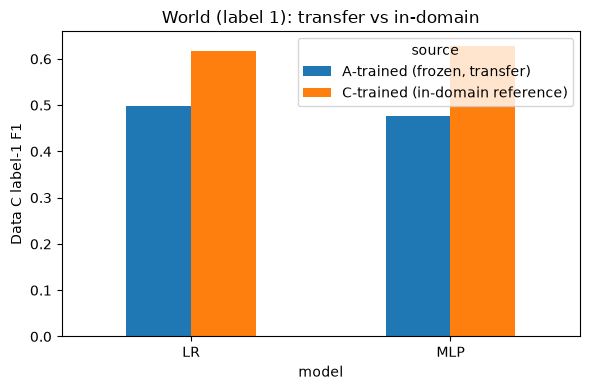

In [61]:
cmp_rows = []
for tag in ["lr", "mlp"]:
    for source, yp in [("A-trained (frozen, transfer)", PRED_C[tag]), ("C-trained (in-domain reference)", REF_PRED[tag])]:
        l1 = u.label_prf(y_c_test, yp, label=1, labels=[1, 2, 3, 4, 5])
        f1_lo, f1_hi = u.bootstrap_ci(y_c_test, yp, lambda a, b: u.label_prf(a, b, 1)["f1"], n_boot=500, seed=SEED)
        cmp_rows.append({"model": tag.upper(), "source": source,
                         "label1_recall": l1["recall"], "label1_precision": l1["precision"], "label1_f1": l1["f1"],
                         "label1_f1_95ci": f"[{f1_lo:.3f}, {f1_hi:.3f}]",
                         "overall_macro_f1_1to4": u.overall_metrics(y_c_test, yp)["macro_f1"],
                         "shared_macro_f1_2to4": u.shared_label_metrics(y_c_test, yp)["macro_f1"],
                         "pct_pred_label5": u.pct_predicted(yp, 5)})
compare_df = pd.DataFrame(cmp_rows)
compare_df.to_csv("results/part4/transfer_vs_reference.csv", index=False)
display(compare_df.round(4))

ax = compare_df.pivot(index="model", columns="source", values="label1_f1").plot.bar(rot=0, figsize=(6, 4))
ax.set_ylabel("Data C label-1 F1"); ax.set_title("World (label 1): transfer vs in-domain"); plt.tight_layout()
plt.savefig("results/part4/label1_transfer_vs_reference.png", dpi=150); plt.show()

with open("results/part4/part4_results.json", "w") as f:
    json.dump({"seed": SEED, "transfer": rows, "reference_info": REF_INFO, "comparison": cmp_rows}, f, indent=2, default=float)

### Unit tests for the Part 4 helpers (Need to Delete before Final)

In [62]:
# Tests
# 1. Frozen models were not changed by anything in this notebook
for tag, m in FINAL_MODELS.items():
    assert model_fingerprint(m) == FROZEN_FP[tag], f"{tag} weights changed!"
# 2. Vectorizer was only used with transform()
assert dict(vec_full.vocabulary_) == VOCAB_SNAPSHOT
assert X_c_test.shape[1] == len(VOCAB_SNAPSHOT)
# 3. Predictions are deterministic and in the Data A label space
for tag, m in FINAL_MODELS.items():
    assert (predict(m, X_c_test) == PRED_C[tag]).all()
    assert set(PRED_C[tag]) <= {1, 2, 3, 4, 5}
# 4. Reference models only ever output Data C labels
for tag in REF_PRED:
    assert set(REF_PRED[tag]) <= {1, 2, 3, 4}
# 5. Metric consistency: label-1 'predicted as' row sums to support; confusion rows match class counts
for tag, yp in PRED_C.items():
    l1 = u.label_prf(y_c_test, yp, 1)
    assert sum(l1["predicted_as"].values()) == l1["support"] == int((y_c_test == 1).sum())
    assert (u.rect_confusion(y_c_test, yp).sum(axis=1) == np.bincount(y_c_test)[1:5]).all()
# 6. Shared-label evaluation really excludes label-1 rows
assert transfer_df["shared_n"].iloc[0] == int(np.isin(y_c_test, [2, 3, 4]).sum())
# 7. Error samples: >= 10 (or all, if fewer exist) and all genuine World errors
for tag, yp in PRED_C.items():
    e = pd.read_csv(f"results/part4/label1_errors_{tag}.csv")
    n_err = int(((y_c_test == 1) & (yp != 1)).sum())
    assert len(e) >= min(10, n_err) and (e["Label"] == 1).all() and (e["Predicted"] != 1).all()
# 8. Test set was never used for fitting: C-test texts absent from the reference training data
n_dup = u.text_overlap(u.article_text(C_TEST), u.article_text(C_TRAIN))
if n_dup: print(f"WARNING: {n_dup} C-test texts also appear in C train (report this; it inflates the in-domain reference)")
print("all Part 4 self-tests passed")

all Part 4 self-tests passed


In [63]:
import inspect
_tests = [(k, v) for k, v in sorted(globals().items())
          if k.startswith("test_") and inspect.isfunction(v)]
for _name, _fn in _tests:
    _fn()
print(f"all {len(_tests)} helper unit tests passed")
from sklearn.metrics import classification_report


# 10 Data C style rows: true labels and the predictions of some Data A model (labels 1-5)
Y_TRUE = np.array([1, 1, 1, 1, 2, 2, 3, 3, 4, 4])
Y_PRED = np.array([1, 1, 3, 5, 2, 1, 3, 3, 4, 5])


def test_shared_label_metrics():
    m = u.shared_label_metrics(Y_TRUE, Y_PRED)
    assert m["n"] == 6                                  # label-1 rows dropped
    assert abs(m["accuracy"] - 4 / 6) < 1e-12           # 2 wrong (2->1, 4->5)
    # per class: 2: P=1,R=.5,F=2/3 ; 3: P=1,R=1,F=1 ; 4: P=1,R=.5,F=2/3
    assert abs(m["macro_f1"] - (2 / 3 + 1 + 2 / 3) / 3) < 1e-12
    assert abs(m["frac_predicted_outside_shared"] - 2 / 6) < 1e-12


def test_shared_ignores_label1_rows():
    y_p2 = Y_PRED.copy()
    y_p2[:4] = 2                                        # change only true-label-1 predictions
    a, b = u.shared_label_metrics(Y_TRUE, Y_PRED), u.shared_label_metrics(Y_TRUE, y_p2)
    assert a == b


def test_label1_metrics():
    m = u.label_prf(Y_TRUE, Y_PRED, label=1)
    # predicted 1 at rows 0,1,5 -> TP=2, FP=1 ; true 1 = 4 -> FN=2
    assert m["support"] == 4 and m["n_predicted_as_label"] == 3
    assert abs(m["precision"] - 2 / 3) < 1e-12 and abs(m["recall"] - 0.5) < 1e-12
    assert abs(m["f1"] - 2 * (2 / 3) * 0.5 / (2 / 3 + 0.5)) < 1e-12
    assert m["predicted_as"] == {1: 2, 2: 0, 3: 1, 4: 0, 5: 1}
    assert sum(m["predicted_as"].values()) == m["support"]


def test_label1_never_predicted_is_zero_not_nan():
    m = u.label_prf(Y_TRUE, np.full(10, 3), label=1)
    assert m["precision"] == 0 and m["recall"] == 0 and m["f1"] == 0


def test_matches_sklearn_report():
    rep = classification_report(Y_TRUE, Y_PRED, labels=[1, 2, 3, 4, 5],
                                output_dict=True, zero_division=0)
    for l in [1, 2, 3, 4]:
        m = u.label_prf(Y_TRUE, Y_PRED, label=l)
        assert abs(m["precision"] - rep[str(l)]["precision"]) < 1e-12
        assert abs(m["recall"] - rep[str(l)]["recall"]) < 1e-12


def test_pct_predicted_label5():
    assert u.pct_predicted(Y_PRED, 5) == 20.0
    assert u.pct_predicted([1, 2, 3], 5) == 0.0


def test_overall_metrics_uses_labels_1_to_4():
    m = u.overall_metrics(Y_TRUE, Y_PRED, labels=[1, 2, 3, 4])
    assert abs(m["accuracy"] - 0.6) < 1e-12
    # label 5 predictions hurt recall but 5 itself is not averaged in
    f1s = [u.label_prf(Y_TRUE, Y_PRED, label=l)["f1"] for l in [1, 2, 3, 4]]
    assert abs(m["macro_f1"] - np.mean(f1s)) < 1e-12


def test_rect_confusion_shape_and_sums():
    cm = u.rect_confusion(Y_TRUE, Y_PRED)
    assert cm.shape == (4, 5)
    assert cm.sum() == len(Y_TRUE)
    assert list(cm.sum(axis=1)) == [4, 2, 2, 2]         # row sums = class supports
    assert cm[0].tolist() == [2, 0, 1, 0, 1]            # matches label-1 'predicted_as'


def test_sample_errors():
    df = pd.DataFrame({"Label": Y_TRUE, "Title": list("abcdefghij"),
                       "Description": ["d"] * 10})
    s = u.sample_errors(df, Y_PRED, label=1, n=10, seed=0)
    assert len(s) == 2                                  # only 2 label-1 errors exist
    assert (s["Label"] == 1).all() and (s["Predicted"] != 1).all()
    assert set(s["Predicted"]) == {3, 5}                # round-robin shows both error types
    # reproducible
    s2 = u.sample_errors(df, Y_PRED, label=1, n=10, seed=0)
    assert s["row"].tolist() == s2["row"].tolist()


def test_sample_errors_respects_n():
    rng = np.random.default_rng(1)
    df = pd.DataFrame({"Label": [1] * 50, "Title": ["t"] * 50, "Description": ["d"] * 50})
    pred = rng.choice([2, 3, 4, 5], size=50)
    s = u.sample_errors(df, pred, n=10, seed=0)
    assert len(s) == 10 and s["row"].is_unique


def test_vocab_gap_finds_missing_terms():
    world = ["earthquake hits japan", "earthquake kills dozens", "earthquake relief japan",
             "senate votes bill"]
    politics = ["senate votes bill", "senate passes law", "president signs bill"]
    an = TfidfVectorizer().build_analyzer()
    g = u.vocab_gap(world, politics, an, min_world_df=2)
    top = g.iloc[0]
    assert top["token"] == "earthquake" and top["politics_A_df"] == 0
    assert "senate" not in set(g["token"]) or g.set_index("token").loc["senate", "ratio"] < top["ratio"]


def test_topic_tagging():
    assert "disaster/health" in u.tag_topics("Earthquake strikes southern region")
    assert u.tag_topics("zzz qqq") == ["other"]
    df = pd.DataFrame({"Label": [1, 1, 2], "Title": ["Earthquake in Iran", "Local zzz", "Sports"],
                       "Description": ["x", "y", "z"]})
    tb = u.topic_breakdown(df, np.array([1, 3, 2]))
    assert tb["n_articles"].sum() >= 2 and (tb["n_correct"] <= tb["n_articles"]).all()


def test_normalize_columns_and_article_text():
    raw = pd.DataFrame({"label": [1], "title": ["T"], "description": [None]})
    df = u.normalize_columns(raw)
    assert list(df.columns) == ["Label", "Title", "Description"]
    assert u.article_text(df).iloc[0] == "T "           # missing description is safe
    try:
        u.normalize_columns(pd.DataFrame({"x": [1]}))
        assert False
    except ValueError:
        pass


def test_fingerprint_detects_change():
    w = [np.arange(6, dtype=np.float32).reshape(2, 3), np.ones(3, dtype=np.float32)]
    f0 = u.fingerprint(w)
    assert f0 == u.fingerprint([x.copy() for x in w])
    w[0][0, 0] += 1e-6
    assert u.fingerprint(w) != f0


def test_text_overlap():
    assert u.text_overlap(["a", "b", "c"], ["b", "c", "d"]) == 2


def test_vectorizer_is_not_modified_by_transform():
    vec = TfidfVectorizer().fit(["aaa bbb ccc", "bbb ccc ddd"])
    before = dict(vec.vocabulary_), vec.idf_.copy()
    vec.transform(["zzz new words", "aaa aaa aaa"])
    assert before[0] == vec.vocabulary_ and np.array_equal(before[1], vec.idf_)


def test_bootstrap_ci():
    f = lambda yt, yp: u.label_prf(yt, yp, label=1)["f1"]
    lo, hi = u.bootstrap_ci(Y_TRUE, Y_PRED, f, n_boot=200, seed=0)
    point = f(Y_TRUE, Y_PRED)
    assert 0 <= lo <= hi <= 1 and lo <= point + 0.35 and hi >= point - 0.35
    assert (lo, hi) == u.bootstrap_ci(Y_TRUE, Y_PRED, f, n_boot=200, seed=0)
    perfect = u.bootstrap_ci(Y_TRUE, Y_TRUE, f, n_boot=100)
    assert perfect == (1.0, 1.0)



all 17 helper unit tests passed
